# Models for several counting sites

Can the forecast model of the Warendorfer Straße (notebook 02) forecast other counting sites too,
and is one **global model** for all sites better than **one model per site**?

This notebook uses the 9 sites with data since 2020 or earlier, so that every site has at least
three years of training data before the first test quarter (2023). It compares, with the same
time-based cross-validation as notebook 02:

1. **Naive baseline** per site: same weekday one week earlier
2. **Holiday baseline** per site: naive baseline times a factor per kind of special day off
3. **LightGBM per site**: the model of notebook 02, trained separately for each site
4. **Global LightGBM**: one model for all sites, with counts and lags divided by the median count
   of each site, and the site as a categorical feature

Requires the raw data in `data/raw` (the daily job or `python -m radmuenster.forecast` downloads it).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from radmuenster.data import DEFAULT_SITE, load_intervals, to_daily
from radmuenster.evaluation import cross_validate, summarize, time_series_folds
from radmuenster.explore import PALETTE
from radmuenster.features import PERIOD_STARTS
from radmuenster.models import holiday_baseline, lightgbm, naive_baseline
from radmuenster.multi_site import (
    LONG_HISTORY_SITES,
    SHORT_HISTORY_SITES,
    global_lightgbm,
    per_site,
    site_counts,
    sites_table,
)
from radmuenster.sites import load_all_sites
from radmuenster.weather import load_weather

RAW = Path("..") / "data" / "raw"
all_sites, failed = load_all_sites(cache_dir=RAW)
assert not failed, failed
weather = load_weather(cache_dir=RAW / "weather")

# The Warendorfer Straße keeps its own daily counts (to_daily): only they know
# the direction faults and the known faults. The other sites use the flags of sites.py.
counts = {
    site.name: to_daily(load_intervals(DEFAULT_SITE, cache_dir=RAW)) if site.id == DEFAULT_SITE
    else site_counts(all_sites[all_sites["site_id"] == site.id])
    for site in LONG_HISTORY_SITES
}
SITE_NAMES = list(counts)
print(f"{len(SITE_NAMES)} sites: {', '.join(SITE_NAMES)}")

9 sites: Warendorfer Straße, Hammer Straße, Weseler Straße, Hüfferstraße, Gartenstraße, Neutor, Promenade (nördl. Salzstraße), Kanalpromenade, Abschnitt 5, Hafenstraße


## 1. The sites

Days with a flag (outage, partial day, dead channel, fault status) are left out of training and
evaluation, as at the Warendorfer Straße.

In [2]:
overview = pd.DataFrame({
    name: {
        "first day": daily.index.min().strftime("%Y-%m-%d"),
        "days": len(daily),
        "usable days": f"{daily['complete'].mean():.0%}",
        "median per day": daily.loc[daily["complete"], "count"].median(),
    }
    for name, daily in counts.items()
}).T
overview.sort_values("median per day", ascending=False)

,first day,days,usable days,median per day
Promenade (nördl. Salzstraße),2019-01-01,2848,96%,14568.0
Neutor,2019-01-01,2848,92%,10222.0
Hammer Straße,2019-01-01,2848,98%,7549.5
Hafenstraße,2020-01-01,2483,97%,6899.0
Warendorfer Straße,2019-01-01,2798,90%,6437.0
Hüfferstraße,2019-01-01,2848,97%,5417.0
Weseler Straße,2019-01-01,2848,96%,2986.5
Gartenstraße,2019-01-01,2848,96%,2762.0
"Kanalpromenade, Abschnitt 5",2019-07-09,2659,96%,960.0


The sites differ more than tenfold in size: from a median of about 1,000 trips per day on the
Kanalpromenade to almost 15,000 on the Promenade. A global model has to deal with that.

## 2. Measurement jumps?

At the Warendorfer Straße, the counting site changed twice (June 2024, October 2025); the
model gets the measurement period as a feature. For the other sites no such jumps are known,
and without labelled directions the inbound-share check of the Warendorfer Straße does not work.
Instead: the **share of each site in the total of all nine sites**, on days when all nine have
usable data. Weather, holidays and the season affect all sites alike and cancel out; a counting
site that suddenly counts more or less shows up as a lasting step in its share.

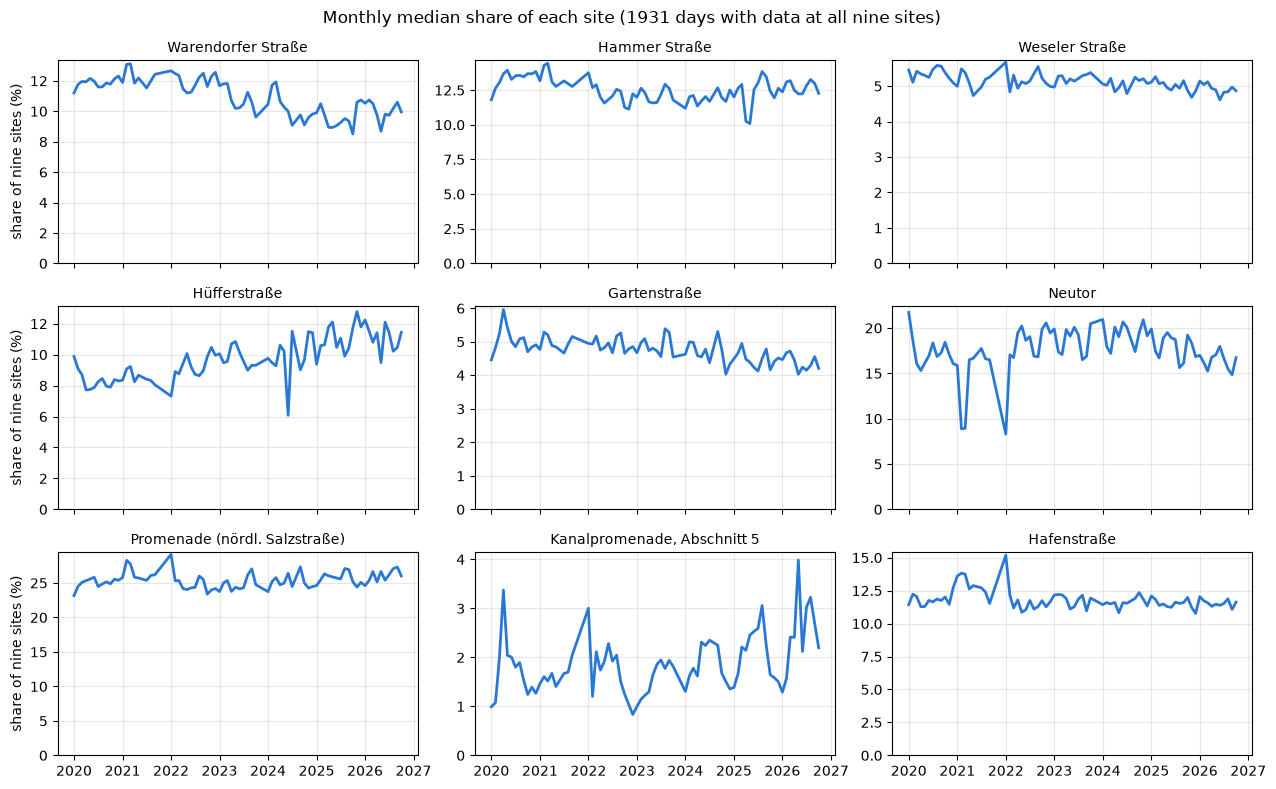

In [3]:
complete_counts = pd.DataFrame({name: daily["count"].where(daily["complete"]) for name, daily in counts.items()})
complete_counts = complete_counts.dropna()
share = complete_counts.div(complete_counts.sum(axis=1), axis=0)
monthly_share = share.groupby(share.index.to_period("M")).median()
monthly_share.index = monthly_share.index.to_timestamp()

fig, axes = plt.subplots(3, 3, figsize=(13, 8), sharex=True)
for ax, name in zip(axes.flat, SITE_NAMES):
    ax.plot(monthly_share.index, monthly_share[name] * 100, color=PALETTE["light"][0], lw=2)
    ax.set_title(name, fontsize=10)
    ax.set_ylim(0, None)
    ax.grid(alpha=0.3)
for ax in axes[:, 0]:
    ax.set_ylabel("share of nine sites (%)")
fig.suptitle(f"Monthly median share of each site ({len(complete_counts)} days with data at all nine sites)")
fig.tight_layout()
plt.show()

Apart from the known changes at the Warendorfer Straße, no site shows a sharp, lasting step.
What the shares do show:

- **Short dips are outages that the flags miss.** The Neutor drops to about half its share in early
  and in late 2021 (an outage of 2021 that the flags only partly catch), the Hüfferstraße
  in mid-2024 and the Hammer Straße in early 2025 for a month or two. Because a share is relative
  to all nine sites, the other sites rise at the same time (e.g. the Hafenstraße and the Promenade
  in early 2021 and early 2022). These days stay in the training data; the 2021 dips lie before
  the first test quarter.
- **The Kanalpromenade** swings with the season (higher in summer, probably a leisure route) and
  grows over the years.
- **The Hüfferstraße** grows from about 8 % to about 11 % since 2021, gradually and not in one
  step, which looks more like traffic than like a new counter.

So no measurement periods are added for any of the other eight sites.

## 3. Comparison

The same folds for all models: each quarter from 2023 on is a test period, trained on all days
before it. MAE is in trips per day, WAPE is the sum of errors divided by the sum of actual counts,
which makes the sites comparable.

In [4]:
table = sites_table(counts, weather, period_starts={"Warendorfer Straße": PERIOD_STARTS})
print(f"{len(table)} rows (site days), {table.shape[1] - 2} features")

MODELS = {
    "naive baseline": per_site(naive_baseline),
    "holiday baseline": per_site(holiday_baseline),
    "LightGBM per site": per_site(lightgbm),
    "global LightGBM": global_lightgbm,
}
predictions = {name: cross_validate(model, table, keep=("site",)) for name, model in MODELS.items()}

overall = pd.concat({name: summarize(p).iloc[0] for name, p in predictions.items()}, axis=1).T
overall["n_days"] = overall["n_days"].astype(int)
overall.style.format({"mae": "{:.0f}", "wape": "{:.1%}", "mape": "{:.1%}", "nrmse": "{:.1%}"})

23871 rows (site days), 25 features


,n_days,mae,wape,mape,nrmse
naive baseline,11803,1160,17.9%,32.1%,29.6%
holiday baseline,11803,1050,16.2%,26.1%,25.1%
LightGBM per site,11803,582,9.0%,13.1%,13.8%
global LightGBM,11803,591,9.1%,14.3%,14.1%


In [5]:
by_site = {name: summarize(p, by="site") for name, p in predictions.items()}
wape = pd.DataFrame({name: s["wape"] for name, s in by_site.items()}).sort_values("LightGBM per site")
mae = pd.DataFrame({name: s["mae"] for name, s in by_site.items()}).loc[wape.index]
pd.concat({"MAE (trips)": mae.round(0), "WAPE (%)": (wape * 100).round(1)}, axis=1)

MAE (trips)                   \
                              naive baseline holiday baseline   
site                                                            
Hafenstraße                            904.0            836.0   
Promenade (nördl. Salzstraße)         2477.0           2231.0   
Gartenstraße                           465.0            412.0   
Weseler Straße                         550.0            502.0   
Warendorfer Straße                     957.0            847.0   
Neutor                                1962.0           1785.0   
Hammer Straße                         1309.0           1164.0   
Hüfferstraße                          1397.0           1248.0   
Kanalpromenade, Abschnitt 5            421.0            424.0   

                                                                 \
                              LightGBM per site global LightGBM   
site                                                              
Hafenstraße                               450.0           476.0   
Promenade (nördl. Salzstraße)            1073.0          1103.0   
Gartenstraße                              222.0           221.0   
Weseler Straße                            247.0           256.0   
Warendorfer Straße                        524.0           501.0   
Neutor                                    948.0          1021.0   
Hammer Straße                             727.0           644.0   
Hüfferstraße                              827.0           876.0   
Kanalpromenade, Abschnitt 5               218.0           221.0   

                                    WAPE (%)                   \
                              naive baseline holiday baseline   
site                                                            
Hafenstraße                             13.3             12.3   
Promenade (nördl. Salzstraße)           16.7             15.1   
Gartenstraße                            17.3             15.3   
Weseler Straße                          18.8             17.2   
Warendorfer Straße                      16.0             14.2   
Neutor                                  18.5             16.8   
Hammer Straße                           18.0             16.0   
Hüfferstraße                            22.7             20.3   
Kanalpromenade, Abschnitt 5             33.6             33.8   

                                                                 
                              LightGBM per site global LightGBM  
site                                                             
Hafenstraße                                 6.6             7.0  
Promenade (nördl. Salzstraße)               7.2             7.4  
Gartenstraße                                8.3             8.2  
Weseler Straße                              8.4             8.8  
Warendorfer Straße                          8.8             8.4  
Neutor                                      8.9             9.6  
Hammer Straße                              10.0             8.9  
Hüfferstraße                               13.4            14.2  
Kanalpromenade, Abschnitt 5                17.4            17.6

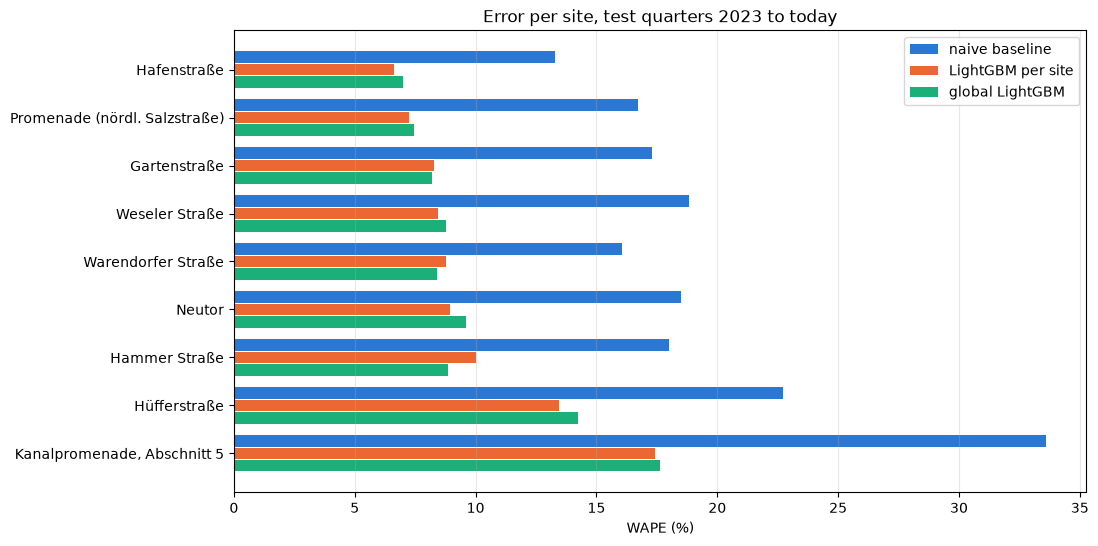

In [6]:
# The same colour per model as in the table order; the holiday baseline is left out
# of the plot, it is close to the naive baseline
SHOWN = ["naive baseline", "LightGBM per site", "global LightGBM"]
COLORS = dict(zip(SHOWN, PALETTE["light"]))

fig, ax = plt.subplots(figsize=(11, 6))
height = 0.26
y = np.arange(len(wape))
for i, name in enumerate(SHOWN):
    ax.barh(y + (i - 1) * height, wape[name] * 100, height=height * 0.9, color=COLORS[name], label=name)
ax.set_yticks(y, wape.index)
ax.invert_yaxis()
ax.set_xlabel("WAPE (%)")
ax.set_title("Error per site, test quarters 2023 to today")
ax.legend(loc="upper right")
ax.grid(axis="x", alpha=0.3)
plt.show()

LightGBM roughly halves the error of the naive baseline at every site. The sites differ a lot,
though: the Promenade and the Hafenstraße are forecast best, the Kanalpromenade and the
Hüfferstraße worst. The Kanalpromenade is small and swings with the season, the Hüfferstraße
grows (section 2): a level that keeps moving is harder to forecast.

The model of the Warendorfer Straße is the same as in notebook 02; its error here is close to
the published 529 trips, with a few more test days.

## 4. Global model or one model per site?

In [7]:
diff = pd.DataFrame({
    "WAPE per site (%)": wape["LightGBM per site"] * 100,
    "WAPE global (%)": wape["global LightGBM"] * 100,
})
diff["global minus per site (points)"] = diff["WAPE global (%)"] - diff["WAPE per site (%)"]
diff.round(1).sort_values("global minus per site (points)")

,WAPE per site (%),WAPE global (%),global minus per site (points)
site,,,
Hammer Straße,10.0,8.9,-1.1
Warendorfer Straße,8.8,8.4,-0.4
Gartenstraße,8.3,8.2,-0.1
Promenade (nördl. Salzstraße),7.2,7.4,0.2
"Kanalpromenade, Abschnitt 5",17.4,17.6,0.2
Weseler Straße,8.4,8.8,0.3
Hafenstraße,6.6,7.0,0.4
Neutor,8.9,9.6,0.7
Hüfferstraße,13.4,14.2,0.8


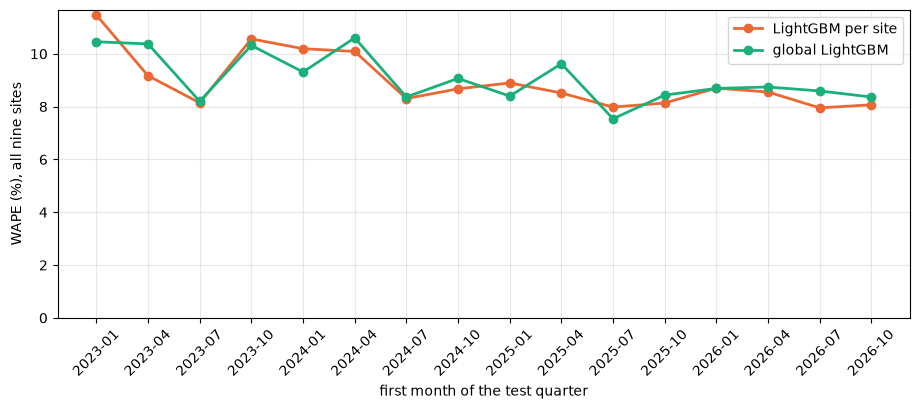

In [8]:
folds = [table.index[test].min() for _, test in time_series_folds(table.index)]
by_fold = pd.DataFrame({name: summarize(predictions[name], by="fold")["wape"] * 100 for name in SHOWN[1:]})
by_fold.index = [f"{start:%Y-%m}" for start in folds]

fig, ax = plt.subplots(figsize=(11, 4))
for name in SHOWN[1:]:
    ax.plot(by_fold.index, by_fold[name], marker="o", lw=2, color=COLORS[name], label=name)
ax.set_ylabel("WAPE (%), all nine sites")
ax.set_xlabel("first month of the test quarter")
ax.set_ylim(0, None)
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Over all nine sites the two approaches are about equally good: the global model is better at
some sites and worse at others, by about one percentage point at most, and neither wins every
quarter. With four or more years of history, each site has enough data of its own; pooling the
sites does not add much.

## 5. Sites with a short history

The other 14 sites have data since 2023 or 2024 only: the Wolbecker Straße since January 2023,
all others since November 2023 to January 2024. That is too little for the folds above, so here the
test quarters start in **2025**, when every site has about a year of training data. Both models now
see all 23 sites: LightGBM per site trains on the data of one site, the global model on all of them.

Two sites have much less usable data: at the Wolbecker Straße the outbound channel has counted
almost nothing since August 2025 (dead channel, flagged), and the Bismarckallee has no data at all
from February 2025 to May 2026.

In [9]:
short_names = [site.name for site in SHORT_HISTORY_SITES]
all_counts = counts | {name: site_counts(all_sites[all_sites["site_name"] == name]) for name in short_names}
pd.DataFrame({
    name: {
        "first day": all_counts[name].index.min().strftime("%Y-%m-%d"),
        "usable days": int(all_counts[name]["complete"].sum()),
        "share usable": f"{all_counts[name]['complete'].mean():.0%}",
        "median per day": all_counts[name].loc[all_counts[name]["complete"], "count"].median(),
    }
    for name in short_names
}).T.sort_values("median per day", ascending=False)

,first day,usable days,share usable,median per day
Promenade (westl. Hals),2023-11-07,1013,94%,10077.0
Wolbecker Straße,2023-01-01,932,67%,9478.0
Coesfelder Kreuz,2024-01-04,992,97%,6213.0
Bismarckallee,2024-01-09,506,50%,5777.5
Bohlweg,2023-12-01,981,93%,4735.0
Lütkenbecker Weg,2023-12-01,984,93%,3561.5
Gasselstiege,2023-12-01,1000,95%,2883.0
Schmeddingstraße,2023-12-01,995,94%,2859.0
Goldstraße,2023-12-01,919,87%,1559.0
"Kanalpromenade, Abschnitt 1 (Dingstiege)",2023-11-14,993,93%,1473.0


In [10]:
SHORT_TEST_START = pd.Timestamp("2025-01-01")
all_table = sites_table(all_counts, weather, period_starts={"Warendorfer Straße": PERIOD_STARTS})
SHORT_MODELS = {name: MODELS[name] for name in ["naive baseline", "LightGBM per site", "global LightGBM"]}
all_predictions = {
    name: cross_validate(model, all_table, keep=("site",), first_test_start=SHORT_TEST_START)
    for name, model in SHORT_MODELS.items()
}

history = lambda p: p["site"].isin(short_names).map({True: "short history (14)", False: "long history (9)"})
(pd.DataFrame({name: summarize(p, by=history(p))["wape"] for name, p in all_predictions.items()}) * 100).round(1)

,naive baseline,LightGBM per site,global LightGBM
site,,,
long history (9),18.1,8.4,8.6
short history (14),20.7,11.5,9.9


WAPE in %, test quarters 2025 to today. For the long sites both models are about equally good,
as before. For the short sites the **global model is clearly better**: it can use what it learned
at the long sites, e.g. how a holiday or a rainy Sunday changes the count.

In [11]:
short_predictions = {name: p[p["site"].isin(short_names)] for name, p in all_predictions.items()}
short_wape = pd.DataFrame({name: summarize(p, by="site")["wape"] * 100 for name, p in short_predictions.items()})
short_wape["global minus per site (points)"] = short_wape["global LightGBM"] - short_wape["LightGBM per site"]
short_wape.round(1).sort_values("global LightGBM")

,naive baseline,LightGBM per site,global LightGBM,global minus per site (points)
site,,,,
Wolbecker Straße,15.9,6.6,6.7,0.2
Bohlweg,16.4,9.3,6.9,-2.4
Bismarckallee,16.6,12.4,9.0,-3.4
Kinderhauser Straße,17.1,10.7,9.1,-1.6
Weißenburgstraße,19.3,9.7,9.2,-0.5
Schmeddingstraße,21.4,10.5,9.8,-0.7
Gasselstiege,20.5,11.3,10.0,-1.3
Goldstraße,19.3,11.8,10.0,-1.8
Lütkenbecker Weg,22.6,11.6,10.0,-1.6


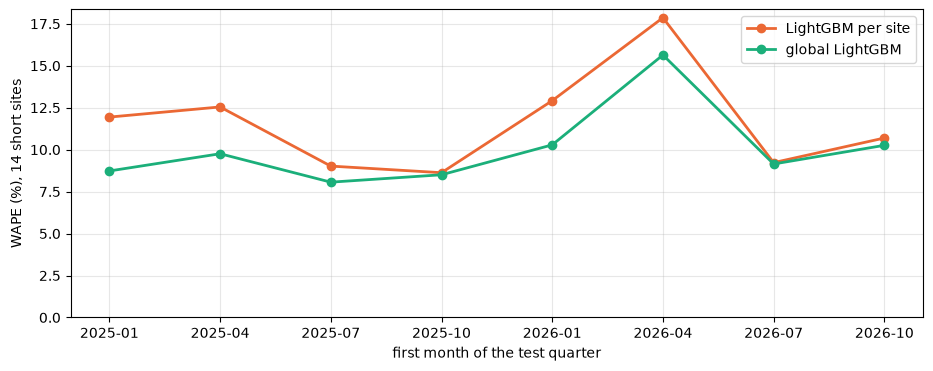

In [12]:
short_folds = [all_table.index[test].min() for _, test in time_series_folds(all_table.index, SHORT_TEST_START)]
short_by_fold = pd.DataFrame({name: summarize(short_predictions[name], by="fold")["wape"] * 100 for name in SHOWN[1:]})
short_by_fold.index = [f"{start:%Y-%m}" for start in short_folds]

fig, ax = plt.subplots(figsize=(11, 4))
for name in SHOWN[1:]:
    ax.plot(short_by_fold.index, short_by_fold[name], marker="o", lw=2, color=COLORS[name], label=name)
ax.set_ylabel("WAPE (%), 14 short sites")
ax.set_xlabel("first month of the test quarter")
ax.set_ylim(0, None)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

The global model is better at 12 of the 14 sites, by up to about 3 points, and better or equal in
every test quarter: by about 3 points in the first half of 2025, when the short sites had only about
a year of data, and again in the first half of 2026, by almost nothing in the other quarters. So the
advantage does not simply shrink with more history; it seems to matter most in winter and spring.
The two exceptions fit the picture: the Wolbecker Straße has data since January 2023, a year more
than the others, and both models are equal there; the Kanalpromenade, Abschnitt 6, the smallest site
(about 600 trips per day) with a strong summer peak, is forecast better by its own model.

The quarter from 2026-04 is worse for both models because of the data, not the models: the
Promenade (westl. Hals) counted only a third to a half of its usual trips from April to May 2026,
and the Goldstraße a fifth to a third of its usual count in May. Only the days with exactly zero
trips are flagged. Like the unflagged dips in section 2, these look like partial outages or building
works that the flags of sites.py do not detect.

## 6. Conclusions

- **Forecasts for other sites work** with the same features: for the nine long sites WAPE between
  about 7 % and 17 %, half the error of the naive baseline everywhere.
- **For sites with a long history, global or per site makes no real difference.** For the 14 sites
  with a short history the **global model is clearly better**, by about 1.5 points over all
  of them and up to 3 points at single sites.
  It is also simpler to run: one model instead of 23, and several times faster to train.
- So a forecast for all 23 sites (step 8b) would use **one global model**.
- **Unflagged outages** are the main problem: several sites have weeks of partial counts that the
  flags miss (section 2, section 5). They make the errors look worse than they are, and a daily
  forecast for such a site would be compared with wrong counts. Before step 8b the flags need a
  rule for partial outages, e.g. a site far below its usual share of all sites for several days.
- **No measurement periods** were found for the other eight long sites (section 2).